# OGC TrainingDML-AI to `Geocroissant` Conversion 🛰️ 🥐

## Introduction

<div style="display: flex; justify-content: space-between; align-items: center; gap: 24px;">
  <div>
    <p style="margin-top: 0;">This notebook performs the reverse transformation of <a href="../GeoCroissant to OGC-TDML/GeoCroissant to OGC-TDML.ipynb">GeoCroissant to OGC-TDML</a>: converting Earth observation training dataset metadata from <a href="https://www.ogc.org/standards/trainingdml-ai">OGC TrainingDML-AI (OGC 20-057r1)</a> into a standard-compliant <a href="https://github.com/mlcommons/croissant">GeoCroissant</a> JSON-LD document.</p>
    <p>We load the OGC-TDML encoding for the <a href="https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars">HLS Burn Scars dataset</a>, map its ISO 19115-1 metadata structures (spectral bands, CRS citation, spatial extent, and pixel-level training data) into Schema.org and GeoCroissant elements, validate it against the Croissant specification, and stream imagery into a PyTorch pipeline.</p>
  </div>
  <img src="../../assets/geocr.jpg" alt="GeoCroissant" width="115" style="border-radius: 8px; flex-shrink: 0;">
</div>

### OGC TrainingDML-AI to GeoCroissant Mapping

| OGC TrainingDML-AI Field | GeoCroissant Field | Schema / Specification | Description |
| :--- | :--- | :--- | :--- |
| `id` / `name` | `name` & `@id` | `sc:name`, `@id` | Dataset identifier and name |
| `description` | `description` | `sc:description` | Textual description of imagery, coverage, and annotations |
| `license` | `license` | `sc:license` | Dataset licensing terms and SPDX URI |
| `version` | `version` | `sc:version` | Semantic version string |
| `providers` | `creator` | `sc:creator` | Organization(s) responsible for dataset production |
| `keywords` | `keywords` | `sc:keywords` | Search keywords for remote sensing and wildfire detection |
| `createdTime` / `updatedTime` | `datePublished` | `sc:datePublished` | Publication timestamp |
| `dataSources` (CRS Citation) | `geocr:coordinateReferenceSystem` | `geocr:coordinateReferenceSystem` | Spatial Coordinate Reference System (e.g. `EPSG:32610`) |
| `extent` (`[west, south, east, north]`) | `spatialCoverage` | `sc:Place` & `sc:GeoShape` box | Spatial bounding box (`south west north east`) |
| `bands` (`List[MD_Band]`) | `geocr:spectralBandMetadata` & `geocr:bandConfiguration` | `geocr:SpectralBand` & `geocr:BandConfiguration` | Spectral band names, center wavelengths, bandwidths, and total band count |
| `dataSources` (Remote archive) | `distribution` (`FileObject`) | `cr:FileObject` | Downloadable ZIP distribution archive with SHA-256 hash |
| `data` (`AI_EOTrainingData` splits) | `distribution` (`FileSet`) | `cr:FileSet` | Structured file sets for train/valid imagery and masks |
| `data[i].dataURL` & `labels[0].imageURL` | `recordSet` (`train_examples`, `valid_examples`) | `cr:RecordSet` & `cr:Field` | RecordSets pairing multi-band images with binary burn masks |

In [ ]:
#!pip install mlcroissant pytdml rasterio torch matplotlib
import glob
import json
import os
import sys
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import mlcroissant as mlc
from mlcroissant._src.core.constants import CROISSANT_CACHE
import numpy as np
from PIL import Image
import rasterio
import torch
from torch.utils.data import DataLoader, IterableDataset

import pytdml
from pytdml.io import read_from_json
from pytdml.type import EOTrainingDataset

print("Libraries imported successfully.")
print(f"pytdml version: {pytdml.__version__}")

Libraries imported successfully.
pytdml version: 1.2.0


## 1. Load OGC TrainingDML-AI metadata

We load the OGC TrainingDML-AI file (`hls_burn_scars_tdml.json`) using `pytdml.io.read_from_json` and inspect its remote sensing properties, tasks, classes, and band definitions:

In [ ]:
tdml_path = "hls_burn_scars_tdml.json"
tdml = read_from_json(tdml_path)

print(f"Dataset ID:         {tdml.id}")
print(f"Dataset Name:       {tdml.name}")
print(f"License:            {tdml.license}")
print(f"Version:            {tdml.version}")
print(f"Extent [W,S,E,N]:   {tdml.extent}")
print(f"Image Size:         {tdml.image_size}")
print(f"Number of Classes:  {tdml.number_of_classes}")
print(f"Classes:            {[(c.key, c.value) for c in tdml.classes]}")
print(f"Task:               {tdml.tasks[0].task_type}")

print(f"\nSpectral Bands ({len(tdml.bands)}):")
for b in tdml.bands:
    code = b.name[0].code if b.name else "unknown"
    print(
        f"  {code:5s} | Peak: {b.peak_response} {b.units} | Range: [{b.bound_min},"
        f" {b.bound_max}] {b.bound_units}"
    )

train_samples = sum(1 for d in tdml.data if d.training_type == "training")
valid_samples = sum(1 for d in tdml.data if d.training_type == "validation")
print(
    f"\nTotal Samples:{len(tdml.data)} (Train: {train_samples}, Valid: {valid_samples})"
)

Dataset ID:         hls-burn-scars
Dataset Name:       Hls Burn Scars
License:            CC BY-SA 4.0
Version:            1.0.0
Extent [W,S,E,N]:   [-124.848974, 24.396308, -66.885444, 49.384358]
Image Size:         512,512,6
Number of Classes:  2
Classes:            [('background', '0'), ('burn_scar', '1')]
Task:               Semantic Segmentation

Spectral Bands (6):
  Blue  | Peak: 490.0 nm | Range: [457.5, 522.5] nm
  Green | Peak: 560.0 nm | Range: [530.0, 590.0] nm
  Red   | Peak: 665.0 nm | Range: [650.0, 680.0] nm
  NIR   | Peak: 865.0 nm | Range: [850.0, 880.0] nm
  SWIR1 | Peak: 1610.0 nm | Range: [1565.0, 1655.0] nm
  SWIR2 | Peak: 2200.0 nm | Range: [2110.0, 2290.0] nm

Total Samples:      804 (Train: 540, Valid: 264)


## 2. Convert OGC TrainingDML-AI to GeoCroissant

We map the OGC TrainingDML-AI dataset into a GeoCroissant `mlc.Metadata` object.

In [ ]:
def tdml_to_geocroissant(tdml_obj: EOTrainingDataset) -> mlc.Metadata:
    """Converts an OGC TrainingDML-AI EOTrainingDataset into a GeoCroissant Metadata object."""
    dataset_id = tdml_obj.id

    # 1. Resolve remote archive URL from dataSources
    archive_url = (
        "https://huggingface.co/datasets/harshinde/hls/resolve/main/hls_burn_scars.zip"
    )
    crs_code = "EPSG:32610"
    for ds in tdml_obj.data_sources or []:
        if ds.alternate_title:
            for at in ds.alternate_title:
                if at.endswith(".zip") or "resolve/main" in at:
                    archive_url = at
                if "EPSG:" in at:
                    crs_code = at
        if ds.title and "EPSG" in ds.title:
            crs_code = ds.title.split("(")[-1].replace(")", "").strip()

    archive_id = f"{dataset_id}-archive"
    archive = mlc.FileObject(
        id=archive_id,
        name=archive_id,
        description=(
            "Remote ZIP archive containing multi-spectral imagery and burn scar masks"
        ),
        content_url=archive_url,
        encoding_formats=["application/zip"],
        sha256="dc1ae02e16dd4b7ec99130135a7887305d9e9a664c0ec521e409da207684e8e3",
    )

    # 2. Define FileSets for train and validation splits
    distribution = [
        archive,
        mlc.FileSet(
            id="train-images",
            name="train-images",
            description="Training multi-spectral GeoTIFF imagery",
            contained_in=[archive_id],
            encoding_formats=["image/tiff"],
            includes=["train/images/*.tif"],
        ),
        mlc.FileSet(
            id="train-masks",
            name="train-masks",
            description="Training wildfire burn scar mask images",
            contained_in=[archive_id],
            encoding_formats=["image/tiff"],
            includes=["train/masks/*.tif"],
        ),
        mlc.FileSet(
            id="valid-images",
            name="valid-images",
            description="Validation multi-spectral GeoTIFF imagery",
            contained_in=[archive_id],
            encoding_formats=["image/tiff"],
            includes=["valid/images/*.tif"],
        ),
        mlc.FileSet(
            id="valid-masks",
            name="valid-masks",
            description="Validation wildfire burn scar mask images",
            contained_in=[archive_id],
            encoding_formats=["image/tiff"],
            includes=["valid/masks/*.tif"],
        ),
    ]

    # 3. Spectral bands: geocr:SpectralBand and geocr:BandConfiguration
    band_names = (
        [b.name[0].code for b in tdml_obj.bands]
        if tdml_obj.bands
        else ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]
    )
    spectral_bands = []
    if tdml_obj.bands:
        for b in tdml_obj.bands:
            bw = (b.bound_max - b.bound_min) if (b.bound_max and b.bound_min) else 50.0
            spectral_bands.append(
                mlc.SpectralBand(
                    name=b.name[0].code,
                    center_wavelength=mlc.QuantitativeValue(
                        value=b.peak_response, unitText=b.units or "nm"
                    ),
                    bandwidth=mlc.QuantitativeValue(
                        value=bw, unitText=b.bound_units or "nm"
                    ),
                )
            )

    band_config = mlc.BandConfiguration(
        total_bands=len(band_names),
        band_names_list=band_names,
    )

    # 4. Helper for paired RecordSets
    def create_split_record_sets(
        split_name: str, img_fileset_id: str, mask_fileset_id: str
    ):
        return [
            mlc.RecordSet(
                id=f"{split_name}_images",
                name=f"{split_name} images",
                spatial_resolution=mlc.QuantitativeValue(value=30, unitText="m"),
                fields=[
                    mlc.Field(
                        id=f"{split_name}/filename",
                        name="filename",
                        data_types=[mlc.DataType.TEXT],
                        source=mlc.Source(
                            file_set=img_fileset_id,
                            extract=mlc.Extract(file_property="filename"),
                        ),
                    ),
                    mlc.Field(
                        id=f"{split_name}/image",
                        name="image",
                        data_types=[mlc.DataType.IMAGE_OBJECT],
                        is_array=True,
                        array_shape="512,512,6",
                        band_configuration=band_config,
                        source=mlc.Source(
                            file_set=img_fileset_id,
                            extract=mlc.Extract(file_property="content"),
                        ),
                    ),
                ],
            ),
            mlc.RecordSet(
                id=f"{split_name}_masks",
                name=f"{split_name} masks",
                fields=[
                    mlc.Field(
                        id=f"{split_name}/mask_filename",
                        name="mask_filename",
                        data_types=[mlc.DataType.TEXT],
                        source=mlc.Source(
                            file_set=mask_fileset_id,
                            extract=mlc.Extract(file_property="filename"),
                        ),
                    ),
                    mlc.Field(
                        id=f"{split_name}/mask",
                        name="mask",
                        data_types=[mlc.DataType.IMAGE_OBJECT],
                        is_array=True,
                        array_shape="512,512,1",
                        band_configuration=mlc.BandConfiguration(
                            total_bands=1,
                            band_names_list=["mask"],
                        ),
                        source=mlc.Source(
                            file_set=mask_fileset_id,
                            extract=mlc.Extract(file_property="content"),
                        ),
                    ),
                ],
            ),
            mlc.RecordSet(
                id=f"{split_name}_examples",
                name=f"{split_name} examples",
                fields=[
                    mlc.Field(
                        id=f"{split_name}_examples/image_key",
                        name="image_key",
                        data_types=[mlc.DataType.TEXT],
                        source=mlc.Source(
                            field=f"{split_name}/filename",
                            transforms=[
                                mlc.Transform(regex=r"^(.+?)(?:_merged\.tif)?$")
                            ],
                        ),
                        references=mlc.Source(
                            field=f"{split_name}/mask_filename",
                            transforms=[
                                mlc.Transform(regex=r"^(.+?)(?:\.mask\.tif)?$")
                            ],
                        ),
                    ),
                    mlc.Field(
                        id=f"{split_name}_examples/image",
                        name="image",
                        data_types=[mlc.DataType.IMAGE_OBJECT],
                        is_array=True,
                        array_shape="512,512,6",
                        band_configuration=band_config,
                        source=mlc.Source(field=f"{split_name}/image"),
                    ),
                    mlc.Field(
                        id=f"{split_name}_examples/mask",
                        name="mask",
                        data_types=[mlc.DataType.IMAGE_OBJECT],
                        is_array=True,
                        array_shape="512,512,1",
                        band_configuration=mlc.BandConfiguration(
                            total_bands=1,
                            band_names_list=["mask"],
                        ),
                        source=mlc.Source(field=f"{split_name}/mask"),
                    ),
                ],
            ),
        ]

    record_sets = [
        *create_split_record_sets("train", "train-images", "train-masks"),
        *create_split_record_sets("valid", "valid-images", "valid-masks"),
    ]

    # 5. Spatial extent: [west, south, east, north] -> box: "south west north east"
    if tdml_obj.extent and len(tdml_obj.extent) == 4:
        west, south, east, north = tdml_obj.extent
        box_str = f"{south} {west} {north} {east}"
    else:
        box_str = "24.396308 -124.848974 49.384358 -66.885444"

    # 6. Creators
    creators = [
        {"@type": "sc:Organization", "name": p}
        for p in (tdml_obj.providers or ["NASA", "IBM"])
    ]

    # 7. Build Metadata
    return mlc.Metadata(
        name=tdml_obj.id,
        description=tdml_obj.description,
        conforms_to=[
            "http://mlcommons.org/croissant/1.1",
            "http://mlcommons.org/croissant/RAI/",
            "http://mlcommons.org/croissant/geo/",
        ],
        cite_as=tdml_obj.doi or "HLS Foundation Burnscars Dataset (NASA/IBM)",
        license="https://creativecommons.org/licenses/by/4.0/",
        version=tdml_obj.version or "1.0.0",
        date_published=tdml_obj.created_time or "2024-01-01",
        keywords=tdml_obj.keywords or ["geospatial", "remote sensing", "burn scars"],
        creators=creators,
        coordinate_reference_system=crs_code,
        spatial_resolution=mlc.QuantitativeValue(value=30, unitText="m"),
        temporal_resolution="P16D",
        band_configuration=band_config,
        spectral_band_metadata=spectral_bands,
        spatial_coverage={
            "@type": "Place",
            "geo": {
                "@type": "GeoShape",
                "box": box_str,
            },
        },
        distribution=distribution,
        record_sets=record_sets,
    )


# Execute conversion
geocr_meta = tdml_to_geocroissant(tdml)
print(f"Successfully converted OGC-TDML to GeoCroissant Metadata: {geocr_meta.name}")
print(f"Conforms to:{geocr_meta.conforms_to}")
print(f"CRS:{geocr_meta.coordinate_reference_system}")
print(
    "Bands"
    f" ({len(geocr_meta.band_configuration.band_names_list)}):{geocr_meta.band_configuration.band_names_list}"
)
print(
    "RecordSets"
    f" ({len(geocr_meta.record_sets)}):{[rs.name for rs in geocr_meta.record_sets]}"
)

Successfully converted OGC-TDML to GeoCroissant Metadata: hls-burn-scars
Conforms to:        ['http://mlcommons.org/croissant/1.1', 'http://mlcommons.org/croissant/RAI/', 'http://mlcommons.org/croissant/geo/']
CRS:                EPSG:32610
Bands (6):           ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
RecordSets (6):     ['train images', 'train masks', 'train examples', 'valid images', 'valid masks', 'valid examples']


## 3. Serialize and validate GeoCroissant metadata

We serialize the GeoCroissant metadata to standard JSON-LD and validate it using the `mlcroissant` command-line validator:

In [4]:
# Serialize to JSON-LD
metadata_json = geocr_meta.to_json()
metadata_json["@context"]["containedIn"] = "cr:containedIn"

output_json = "hls_burn_scars_geocroissant.json"
with open(output_json, "w", encoding="utf-8") as f:
    json.dump(metadata_json, f, indent=2)

print(
    "GeoCroissant JSON-LD saved to:"
    f" {output_json} ({os.path.getsize(output_json) / 1024:.1f} KB)"
)

# Validate using mlcroissant CLI validator
!mlcroissant validate --jsonld=hls_burn_scars_geocroissant.json

GeoCroissant JSON-LD saved to: hls_burn_scars_geocroissant.json (15.0 KB)


I1107 12:49:07.602207 125438059069888 validate.py:53] Done.


## 4. Load dataset and stream imagery with PyTorch

We load the generated GeoCroissant JSON-LD file via `mlcroissant.Dataset` and stream records into a PyTorch `DataLoader`:

In [5]:
dataset = mlc.Dataset(jsonld=output_json)
print(f"GeoCroissant Dataset loaded: {dataset.metadata.name}")


class HLSDataPipe(IterableDataset):
    """PyTorch IterableDataset streaming directly from GeoCroissant records."""

    def __init__(self, mlc_dataset: mlc.Dataset, record_set_id: str = "train_examples"):
        self.dataset = mlc_dataset
        self.record_set_id = record_set_id

    def __iter__(self):
        records = self.dataset.records(self.record_set_id)
        for record in records:
            img_obj = record[f"{self.record_set_id}/image"]
            mask_obj = record[f"{self.record_set_id}/mask"]

            # Read 6 bands via rasterio (1-indexed): Blue (1), Green (2), Red (3), NIR (4), SWIR1 (5), SWIR2 (6)
            img_data = img_obj.read([1, 2, 3, 4, 5, 6])
            mask_data = np.array(mask_obj)

            raw_key = record[f"{self.record_set_id}/image_key"]
            key_str = (
                raw_key.decode("utf-8") if isinstance(raw_key, bytes) else str(raw_key)
            )

            yield {
                "image_key": key_str,
                "image": torch.tensor(img_data, dtype=torch.float32),
                "mask": torch.tensor(mask_data, dtype=torch.float32),
            }


train_pipe = HLSDataPipe(dataset, "train_examples")
train_loader = DataLoader(train_pipe, batch_size=1)

print("Iterating over PyTorch DataLoader from GeoCroissant...")
samples_list = []
for idx, batch in enumerate(train_loader):
    print(f"Record {idx} loaded:")
    print(f"  Key:        {batch['image_key'][0]}")
    print(f"  Image shape: {batch['image'].shape}")
    print(f"  Mask shape:  {batch['mask'].shape}")

    samples_list.append(batch)
    if len(samples_list) >= 3:
        break

GeoCroissant Dataset loaded: hls-burn-scars
Iterating over PyTorch DataLoader from GeoCroissant...


Record 0 loaded:
  Key:        subsetted_512x512_HLS.S30.T10SDH.2020248.v1.4
  Image shape: torch.Size([1, 6, 512, 512])
  Mask shape:  torch.Size([1, 512, 512])
Record 1 loaded:
  Key:        subsetted_512x512_HLS.S30.T10SEH.2018245.v1.4
  Image shape: torch.Size([1, 6, 512, 512])
  Mask shape:  torch.Size([1, 512, 512])
Record 2 loaded:
  Key:        subsetted_512x512_HLS.S30.T10SEH.2018280.v1.4
  Image shape: torch.Size([1, 6, 512, 512])
  Mask shape:  torch.Size([1, 512, 512])


## 5. Visualize satellite imagery and ground truth masks

We visualize the 3 sample scenes streamed from the newly generated GeoCroissant metadata:

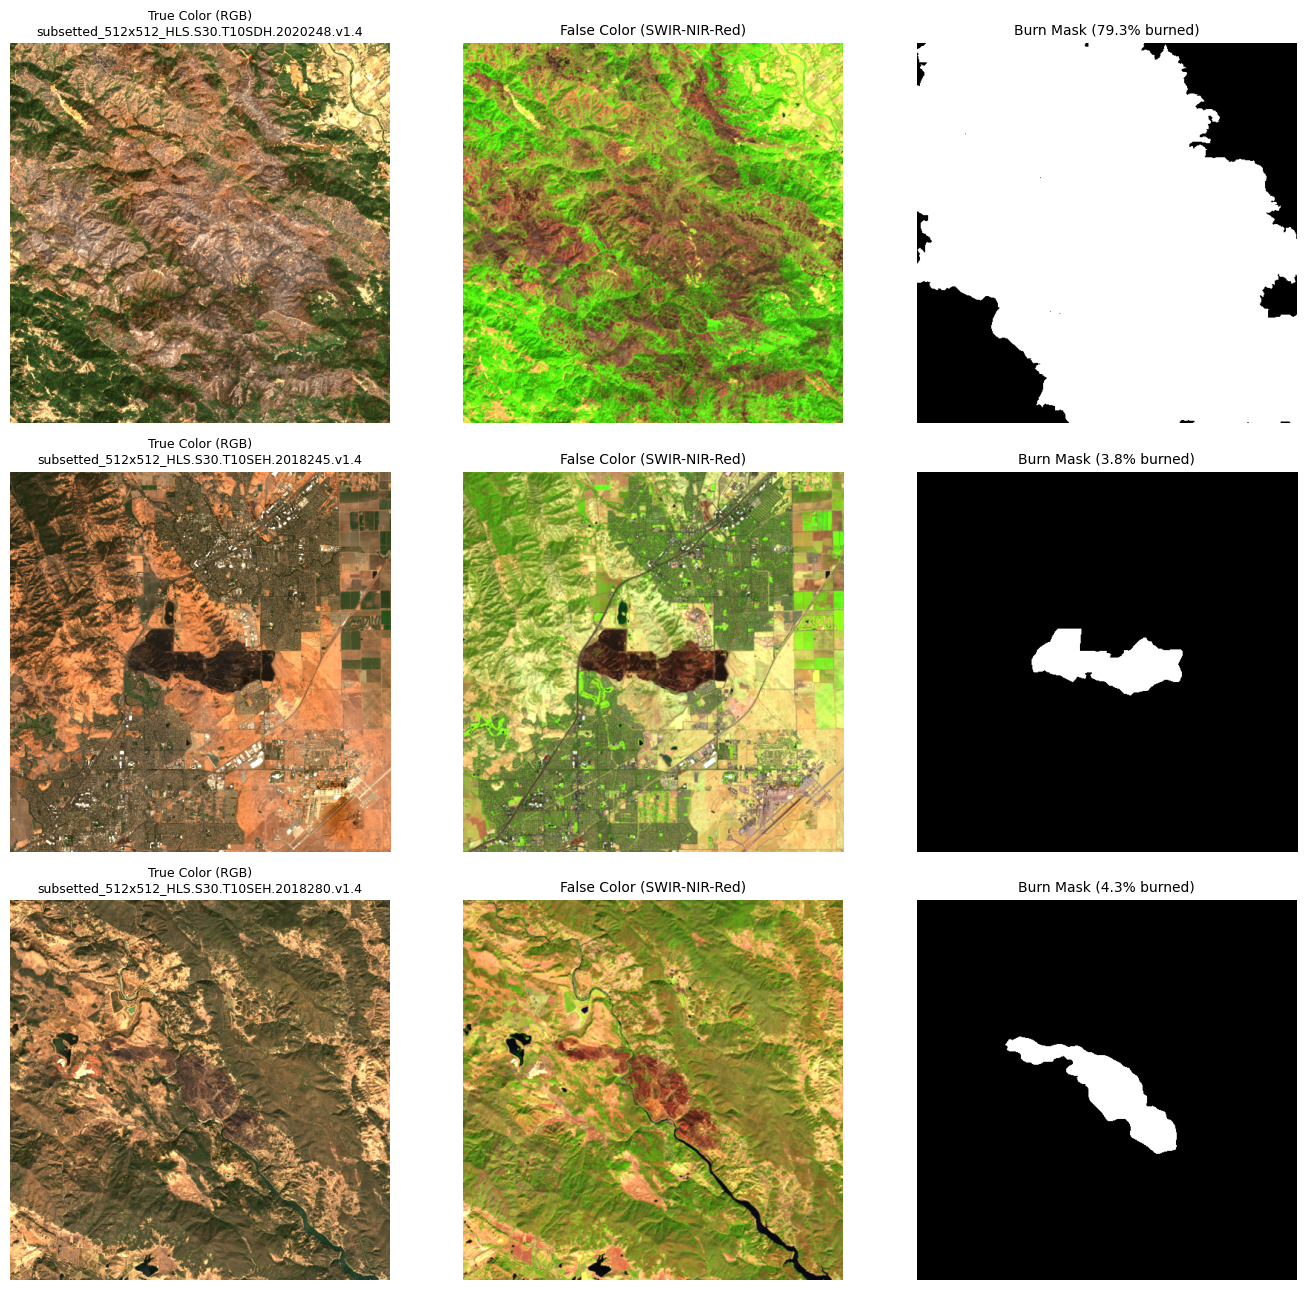

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 13), facecolor="white")

for idx, sample in enumerate(samples_list):
    img = sample["image"][0].numpy()  # shape: [6, 512, 512]
    mask = sample["mask"][0].numpy()  # shape: [512, 512]
    sample_key = sample["image_key"][0]

    # True Color RGB: Bands 3 (Red), 2 (Green), 1 (Blue) -> index 2, 1, 0
    rgb = np.transpose(img[[2, 1, 0], :, :], (1, 2, 0))
    # False Color: Bands 5 (SWIR1), 4 (NIR), 3 (Red) -> index 4, 3, 2
    fc = np.transpose(img[[4, 3, 2], :, :], (1, 2, 0))

    # Apply 98th percentile clipping for contrast
    rgb_vis = np.clip(rgb / np.percentile(rgb, 98), 0, 1)
    fc_vis = np.clip(fc / np.percentile(fc, 98), 0, 1)

    # Binary mask
    mask_bw = (mask.squeeze() > 0).astype(np.uint8)

    # Plot True Color RGB
    axes[idx, 0].imshow(rgb_vis)
    axes[idx, 0].set_title(f"True Color (RGB)\n{sample_key}", fontsize=9, color="black")
    axes[idx, 0].axis("off")

    # Plot False Color Infrared
    axes[idx, 1].imshow(fc_vis)
    axes[idx, 1].set_title("False Color (SWIR-NIR-Red)", fontsize=10, color="black")
    axes[idx, 1].axis("off")

    # Plot Burn Mask
    axes[idx, 2].imshow(mask_bw, cmap="gray", vmin=0, vmax=1)
    burn_pct = 100.0 * (mask_bw.sum() / mask_bw.size)
    axes[idx, 2].set_title(f"Burn Mask", fontsize=10, color="black")
    axes[idx, 2].axis("off")

plt.tight_layout()
plt.show()